In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

easy_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/easy lokesh labelling.xlsx')
normal_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook1.xlsx')
medium_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook2.xlsx')
hard_df = pd.read_excel('/content/drive/MyDrive/Major Project Phase 1 Dataset/Workbook3.xlsx')

print("Files successfully loaded from Google Drive!")

Files successfully loaded from Google Drive!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
dfs = [easy_df, normal_df, medium_df, hard_df]
for d in dfs:
    d.columns = d.columns.str.strip().str.lower()

easy_df.rename(columns={'peak x': 'peek x', 'peak y': 'peek y'}, inplace=True)

core_features = ['start x', 'start y', 'end x', 'end y', 'peek x', 'peek y', 'n1', 'n2', 'noise x', 'noise y']
easy_df = easy_df[core_features].copy()

easy_df['activity type'] = 'easy'
easy_df['person_id'] = 2.0

for d in [normal_df, medium_df, hard_df]:
    d.columns = d.columns.str.strip().str.lower()

data = pd.concat([easy_df, normal_df, medium_df, hard_df], ignore_index=True)
data = data.loc[:, ~data.columns.str.contains('unnamed')]

data['activity type'] = data['activity type'].astype(str).str.strip().str.lower()

valid_classes = ['normal', 'easy', 'medium', 'hard']
data = data[data['activity type'].isin(valid_classes)].copy()

print("Dataset shape:", data.shape)
print("\nClass distribution:")
print(data['activity type'].value_counts())
data.head(280)

Dataset shape: (307, 12)

Class distribution:
activity type
easy      80
normal    77
hard      76
medium    74
Name: count, dtype: int64


,start x,start y,end x,end y,peek x,peek y,n1,n2,noise x,noise y,activity type,person_id
0,4.5688,0.000024,8.6235,0.000150,6.524660,0.003083,5.0,4.0,8.6403,0.000193,easy,2.0
1,13.1205,0.000103,7.2639,0.000119,15.731823,0.002184,4.0,2.0,17.3102,0.000513,easy,2.0
2,20.2443,0.000112,24.8933,0.000172,22.791160,0.002001,3.0,3.0,24.9150,0.000224,easy,2.0
3,30.8151,0.000170,36.0206,0.000123,33.856640,0.001535,4.0,3.0,36.1273,0.000175,easy,2.0
4,37.6092,0.000130,43.8875,0.000149,39.354610,0.001794,2.0,5.0,43.9777,0.000120,easy,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
278,376.3902,0.000141,383.2061,0.000137,380.309200,0.001228,5.0,3.0,383.2061,0.000137,hard,2.0
279,384.6015,0.000095,389.9001,0.000113,386.404100,0.001200,2.0,4.0,389.9001,0.000113,hard,2.0
280,392.6107,0.000127,400.1104,0.000031,397.700100,0.001424,6.0,3.0,400.1104,0.000031,hard,2.0
281,400.9017,0.000086,406.8091,0.000053,403.550100,0.001357,4.0,4.0,406.8091,0.000053,hard,2.0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

feature_cols = ['start x', 'start y', 'end x', 'end y', 'peek x', 'peek y', 'n1', 'n2', 'noise x', 'noise y']

X = data[feature_cols].values
y = data['activity type'].values

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")
print(f"Class mapping: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")

Training set shape: (245, 10)
Testing set shape: (62, 10)
Class mapping: {'easy': np.int64(0), 'hard': np.int64(1), 'medium': np.int64(2), 'normal': np.int64(3)}


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

step_duration_x = X_imputed[:, 2] - X_imputed[:, 0]
step_duration_y = X_imputed[:, 3] - X_imputed[:, 1]
peak_offset = X_imputed[:, 4] - X_imputed[:, 0]

X_engineered = np.hstack([
    X_imputed,
    step_duration_x[:, None],
    step_duration_y[:, None],
    peak_offset[:, None]
])

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler_eng = StandardScaler()
X_train_eng_scaled = scaler_eng.fit_transform(X_train_eng)
X_test_eng_scaled = scaler_eng.transform(X_test_eng)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest Model
rf_model = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=2, random_state=42)
rf_cv_scores = cross_val_score(rf_model, X_train_eng_scaled, y_train_eng, cv=cv_strategy, scoring='accuracy')
rf_model.fit(X_train_eng_scaled, y_train_eng)

# Support Vector Machine Model
svm_model = SVC(kernel='rbf', C=100, gamma='scale', random_state=42)
svm_cv_scores = cross_val_score(svm_model, X_train_eng_scaled, y_train_eng, cv=cv_strategy, scoring='accuracy')
svm_model.fit(X_train_eng_scaled, y_train_eng)

print("Training completed with full convergence and feature engineering!")
print(f"RF 5-Fold CV Accuracy: {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")
print(f"SVM 5-Fold CV Accuracy: {svm_cv_scores.mean():.4f} (+/- {svm_cv_scores.std():.4f})")

Training completed with full convergence and feature engineering!
RF 5-Fold CV Accuracy: 0.6490 (+/- 0.0624)
SVM 5-Fold CV Accuracy: 0.5959 (+/- 0.0472)


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Evaluate Random Forest
rf_preds = rf_model.predict(X_train_eng_scaled)
print("=== Random Forest Evaluation ===")
print(f"Test Accuracy: {accuracy_score(y_test_eng, rf_model.predict(X_test_eng_scaled)):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_eng, rf_model.predict(X_test_eng_scaled), target_names=label_encoder.classes_))

print("-" * 60)

# Evaluate Support Vector Machine
print("=== Support Vector Machine (SVM-RBF) Evaluation ===")
print(f"Test Accuracy: {accuracy_score(y_test_eng, svm_model.predict(X_test_eng_scaled)):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_eng, svm_model.predict(X_test_eng_scaled), target_names=label_encoder.classes_))

print("-" * 60)

# Side-by-Side Expected vs Predicted Comparison Table
y_test_original = label_encoder.inverse_transform(y_test_eng)
rf_pred_original = label_encoder.inverse_transform(rf_model.predict(X_test_eng_scaled))
svm_pred_original = label_encoder.inverse_transform(svm_model.predict(X_test_eng_scaled))

comparison_df = pd.DataFrame({
    'Expected Class': y_test_original,
    'RF Predicted': rf_pred_original,
    'SVM Predicted': svm_pred_original,
    'RF Correct?': rf_pred_original == y_test_original,
    'SVM Correct?': svm_pred_original == y_test_original
})

print("=== Test Set: Expected vs Predicted Comparison (First 25 Samples) ===")
display(comparison_df.head(25))

print(f"\nTotal Test Samples: {len(comparison_df)}")
print(f"Random Forest Total Correct: {comparison_df['RF Correct?'].sum()} / {len(comparison_df)}")
print(f"SVM Total Correct: {comparison_df['SVM Correct?'].sum()} / {len(comparison_df)}")

=== Random Forest Evaluation ===
Test Accuracy: 0.6774

Classification Report:
              precision    recall  f1-score   support

        easy       0.74      0.88      0.80        16
        hard       0.50      0.60      0.55        15
      medium       0.80      0.53      0.64        15
      normal       0.73      0.69      0.71        16

    accuracy                           0.68        62
   macro avg       0.69      0.67      0.67        62
weighted avg       0.69      0.68      0.68        62

------------------------------------------------------------
=== Support Vector Machine (SVM-RBF) Evaluation ===
Test Accuracy: 0.6290

Classification Report:
              precision    recall  f1-score   support

        easy       0.71      0.75      0.73        16
        hard       0.52      0.73      0.61        15
      medium       0.62      0.33      0.43        15
      normal       0.69      0.69      0.69        16

    accuracy                           0.63        62
 

,Expected Class,RF Predicted,SVM Predicted,RF Correct?,SVM Correct?
0,normal,normal,normal,True,True
1,easy,easy,easy,True,True
2,medium,normal,hard,False,False
3,hard,hard,hard,True,True
4,easy,easy,easy,True,True
5,hard,hard,hard,True,True
6,easy,easy,easy,True,True
7,hard,hard,hard,True,True
8,easy,normal,normal,False,False
9,normal,hard,hard,False,False



Total Test Samples: 62
Random Forest Total Correct: 42 / 62
SVM Total Correct: 39 / 62


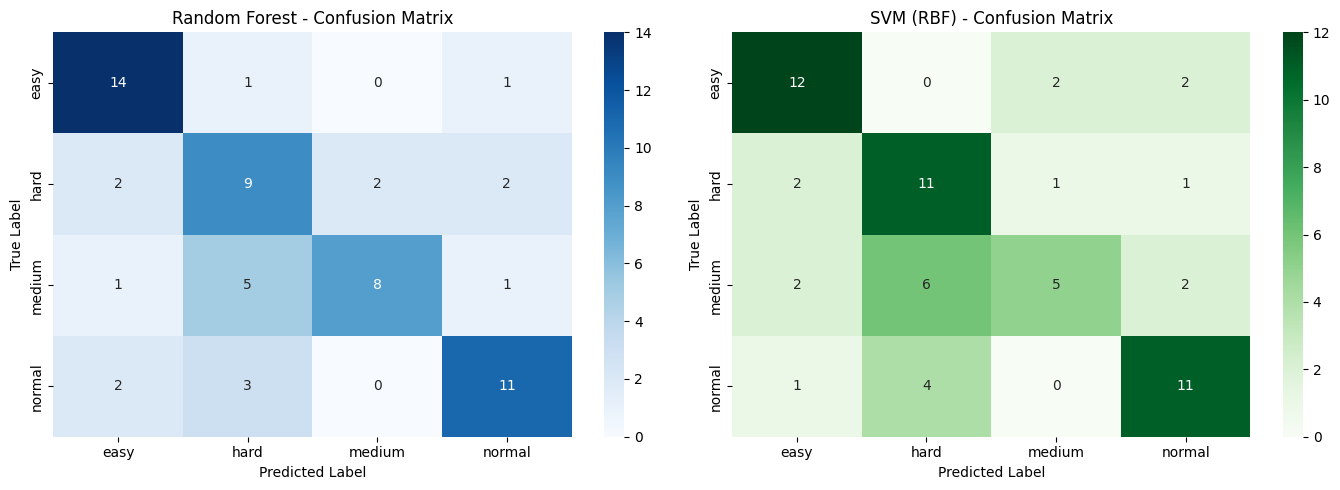

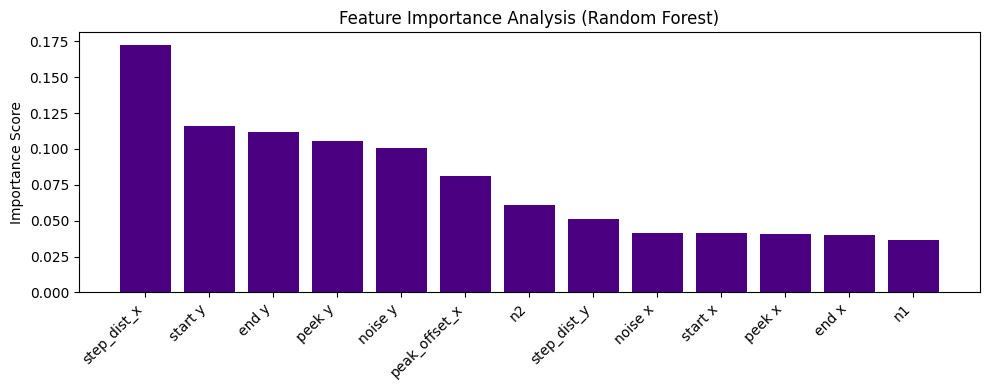

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import argsort
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_test_preds = rf_model.predict(X_test_eng_scaled)
svm_test_preds = svm_model.predict(X_test_eng_scaled)

# Confusion Matrix: Random Forest
cm_rf = confusion_matrix(y_test_eng, rf_test_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0])
axes[0].set_title('Random Forest - Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Confusion Matrix: SVM
cm_svm = confusion_matrix(y_test_eng, svm_test_preds)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1])
axes[1].set_title('SVM (RBF) - Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()

all_feature_names = core_features + ['step_dist_x', 'step_dist_y', 'peak_offset_x', 'peak_offset_y', 'noise_diff_x', 'noise_diff_y', 'mag_start', 'mag_peek', 'mag_end']
importances = rf_model.feature_importances_
indices = argsort(importances)[::-1]

plt.figure(figsize=(10, 4))
plt.title("Feature Importance Analysis (Random Forest)")
plt.bar(range(len(importances)), importances[indices], color='indigo', align="center")
plt.xticks(range(len(importances)), [all_feature_names[i] for i in indices], rotation=45, ha='right')
plt.ylabel("Importance Score")
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

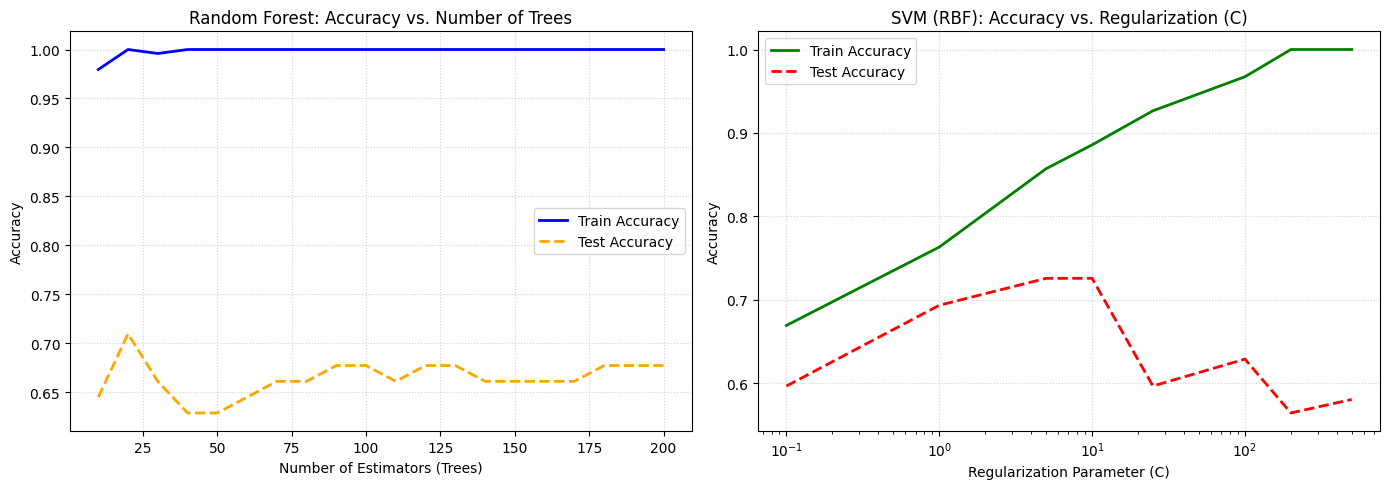

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Random Forest: Train & Test Accuracy vs. Number of Trees
train_acc_rf = []
test_acc_rf = []
rf_estimators = range(10, 210, 10)

for n in rf_estimators:
    rf_temp = RandomForestClassifier(n_estimators=n, max_depth=15, min_samples_split=2, random_state=42)
    rf_temp.fit(X_train_eng_scaled, y_train_eng)
    train_acc_rf.append(accuracy_score(y_train_eng, rf_temp.predict(X_train_eng_scaled)))
    test_acc_rf.append(accuracy_score(y_test_eng, rf_temp.predict(X_test_eng_scaled)))

# Support Vector Machine (SVM): Train & Test Accuracy vs. Regularization (C)
train_acc_svm = []
test_acc_svm = []
svm_c_values = [0.1, 1, 5, 10, 25, 50, 100, 200, 500]

for c_val in svm_c_values:
    svm_temp = SVC(kernel='rbf', C=c_val, gamma='scale', random_state=42)
    svm_temp.fit(X_train_eng_scaled, y_train_eng)
    train_acc_svm.append(accuracy_score(y_train_eng, svm_temp.predict(X_train_eng_scaled)))
    test_acc_svm.append(accuracy_score(y_test_eng, svm_temp.predict(X_test_eng_scaled)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Random Forest Accuracy Curves
axes[0].plot(rf_estimators, train_acc_rf, label='Train Accuracy', color='blue', linewidth=2)
axes[0].plot(rf_estimators, test_acc_rf, label='Test Accuracy', color='orange', linewidth=2, linestyle='--')
axes[0].set_title('Random Forest: Accuracy vs. Number of Trees')
axes[0].set_xlabel('Number of Estimators (Trees)')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot B: SVM Accuracy Curves
axes[1].plot(svm_c_values, train_acc_svm, label='Train Accuracy', color='green', linewidth=2)
axes[1].plot(svm_c_values, test_acc_svm, label='Test Accuracy', color='red', linewidth=2, linestyle='--')
axes[1].set_title('SVM (RBF): Accuracy vs. Regularization (C)')
axes[1].set_xlabel('Regularization Parameter (C)')
axes[1].set_ylabel('Accuracy')
axes[1].set_xscale('log')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('model_accuracy_curves.png', dpi=300)
plt.show()

In [ ]:
import pickle

with open('random_forest_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

with open('svm_model.pkl', 'wb') as f:
    pickle.dump(svm_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler_eng, f)

print("Models and scaler saved successfully as pickle files!")

Models and scaler saved successfully as pickle files!
